Автор: Эркинбеков Айман, Айжигит

# Проект 3. Уровень дохода

Модуль 1, часть Б, командный проект  
Команда: Эркинбеков Айман (уровень C, код), Айжигит (уровень B, код), Омурбек (презентация), Адильхан (уровень A, питчинг)

**Задача.** По данным переписи США предсказать, получает ли человек больше 50 000 долларов в год (`income = >50K`).

**Заказчик.** Банк по модели решает, кому предложить премиальную кредитную карту.

- Предложили человеку с низким доходом (**FP**, ложная тревога) → отказ и расходы на рассылку.
- Пропустили человека с высоким доходом (**FN**, пропуск) → упущенная выгода.
- По стоимости эти ошибки сопоставимы, то есть FP ≈ FN.

Работа состоит из трёх блоков. Блок B строится на разбиении из блока A, блок C опирается на пайплайн из блока B.

| Блок | Что делаем |
| --- | --- |
| A. Базовый | загрузка, разбиение, пропуски, кодирование, логистическая регрессия, матрица ошибок |
| B. Основной | EDA, пайплайн без утечки, две модели на кросс-валидации, метрика и порог, вывод |
| C. Продвинутый | все проблемы данных и утечки, дисбаланс, анализ ошибок, ограничения решения |

**Кто что делал:**

| Автор | Части |
| --- | --- |
| Эркинбеков Айман | Блок A (A1-A5); блок B: пайплайн, две модели, метрика и порог, вывод (B2-B5) |
| Айжигит | Блок B: EDA (B1); блок C целиком: проблемы и утечки, дисбаланс, анализ ошибок, ограничения (C1-C4) |

У каждой части в заголовке указан автор, у каждой ячейки кода в первой строке есть комментарий с автором.

In [1]:
# Автор: Эркинбеков Айман, Айжигит (общие импорты)
# --- Библиотеки ---
from pathlib import Path

import numpy as np                 # массивы и математика
import pandas as pd                # таблицы (DataFrame)
import matplotlib.pyplot as plt    # графики

# scikit-learn: всё для машинного обучения
from sklearn.model_selection import (
    train_test_split,     # делит данные на train и test
    StratifiedKFold,      # кросс-валидация с сохранением доли классов
    cross_validate,       # считает метрики на каждом фолде
    cross_val_predict,    # даёт предсказания "вне фолда" для каждой строки train
)
from sklearn.impute import SimpleImputer               # заполнение пропусков
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer          # разная обработка для разных столбцов
from sklearn.pipeline import Pipeline                  # цепочка шагов: обработка -> модель
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone                         # копия модели "с нуля" (не обученная)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # прячем служебные предупреждения sklearn

RANDOM_STATE = 42          # фиксируем случайность, чтобы результаты повторялись
pd.set_option("display.max_columns", 50)

---
# Блок A. Базовый

*Автор: Эркинбеков Айман*

## A1. Загрузка данных

В файле пропуски записаны знаком `?`. Если загрузить файл как обычно, pandas посчитает `?` обычной категорией, и пропусков «не будет». Поэтому указываю `na_values="?"`: тогда `?` превращается в `NaN`.

In [2]:
# Автор: Эркинбеков Айман
# Ищем файл: сначала в папке data рядом с notebooks, потом рядом с самим notebook (для Colab)
candidates = [Path("../data/adult.csv"), Path("data/adult.csv"), Path("adult.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, "Файл adult.csv не найден"

# na_values="?" -> знак вопроса считается пропуском (NaN)
df = pd.read_csv(DATA_PATH, na_values="?")

print("Размер таблицы:", df.shape)   # (строки, столбцы)
display(df.head())

Размер таблицы: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Автор: Эркинбеков Айман
# info() показывает тип каждого столбца и сколько в нём НЕ пустых значений
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [4]:
# Автор: Эркинбеков Айман
# Пропуски по столбцам: количество и доля
missing = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2),
})
display(missing[missing["Пропусков"] > 0])

# Доля классов целевой переменной
print("Доля классов income:")
display(df["income"].value_counts(normalize=True).round(3).to_frame("Доля"))

,Пропусков,"Доля, %"
workclass,1836,5.64
occupation,1843,5.66
native.country,583,1.79


Доля классов income:


,Доля
income,
<=50K,0.759
>50K,0.241


Пропуски есть только в трёх текстовых столбцах: `workclass` (1836), `occupation` (1843) и `native.country` (583). Это 5-6% строк, удалять их жалко, поэтому будем заполнять.

Классы несбалансированы: 76% людей получают `<=50K` и только 24% получают `>50K`. Значит, модель, которая всем говорит «<=50K», уже даст accuracy 0,76. Одной accuracy для оценки мало.

## A2. Целевая переменная и разбиение

Перевожу `income` в числа: 1 = `>50K`, 0 = `<=50K`. Делю данные **до любой обработки**, иначе статистики теста «протекут» в обучение. `stratify=y` сохраняет долю классов 24/76 и в train, и в test.

In [5]:
# Автор: Эркинбеков Айман
# y: 1 если доход >50K, иначе 0
y = (df["income"] == ">50K").astype(int)
# X: все признаки, кроме ответа
X = df.drop(columns="income")

# Отделяем 20% данных в тест. Тест больше не трогаем до самой финальной проверки.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,               # одинаковая доля классов в train и test
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Доля >50K в train: {y_train.mean():.3f}, в test: {y_test.mean():.3f}")

Train: (26048, 14)  Test: (6513, 14)
Доля >50K в train: 0.241, в test: 0.241


## A3. Заполнение пропусков

Заполняю `workclass`, `occupation`, `native.country` самым частым значением. Важно: `fit` только на train. Imputer запоминает самое частое значение **по train**, а затем этим же значением заполняет и test.

In [6]:
# Автор: Эркинбеков Айман
cat_missing_cols = ["workclass", "occupation", "native.country"]

imputer = SimpleImputer(strategy="most_frequent")
imputer.fit(X_train[cat_missing_cols])        # учимся ТОЛЬКО на train

# Какие значения imputer будет подставлять
print(dict(zip(cat_missing_cols, imputer.statistics_)))

# Применяем к обеим частям (на копиях, исходные X_train/X_test не портим)
X_train_a = X_train.copy()
X_test_a = X_test.copy()
X_train_a[cat_missing_cols] = imputer.transform(X_train[cat_missing_cols])
X_test_a[cat_missing_cols] = imputer.transform(X_test[cat_missing_cols])

print("Пропусков после заполнения: train =", X_train_a.isna().sum().sum(),
      ", test =", X_test_a.isna().sum().sum())

{'workclass': 'Private', 'occupation': 'Prof-specialty', 'native.country': 'United-States'}
Пропусков после заполнения: train = 0 , test = 0


## A4. Кодирование и масштабирование

- **OneHotEncoder** для текстовых столбцов: каждая категория становится отдельным столбцом из 0 и 1. Модель умеет работать только с числами.
- **StandardScaler** для чисел: приводит каждый признак к среднему 0 и стандартному отклонению 1. Без этого `fnlwgt` (сотни тысяч) «перекричит» `age` (десятки) в логистической регрессии.

Оба шага собираю в `ColumnTransformer`, он сам применяет нужное преобразование к нужным столбцам.

In [7]:
# Автор: Эркинбеков Айман
# Делим столбцы на числовые и текстовые автоматически по типу
num_cols = X_train_a.select_dtypes(include="number").columns.tolist()
cat_cols = X_train_a.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", num_cols)
print("Текстовые:", cat_cols)

preprocess_a = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    # handle_unknown="ignore": если в test встретится новая категория, будут все нули, а не ошибка
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# fit на train, transform на test
X_train_enc = preprocess_a.fit_transform(X_train_a)
X_test_enc = preprocess_a.transform(X_test_a)
print("После кодирования: train", X_train_enc.shape, ", test", X_test_enc.shape)

Числовые: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Текстовые: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']
После кодирования: train (26048, 105) , test (6513, 105)


## A5. Логистическая регрессия

Логистическая регрессия считает взвешенную сумму признаков и превращает её в вероятность от 0 до 1 через сигмоиду. Если вероятность ≥ 0,5, модель говорит «>50K».

Accuracy: 0.856
TN=4606  FP=339  FN=600  TP=968
Модель нашла 968 из 1568 людей с доходом >50K, это 61.7% (recall)


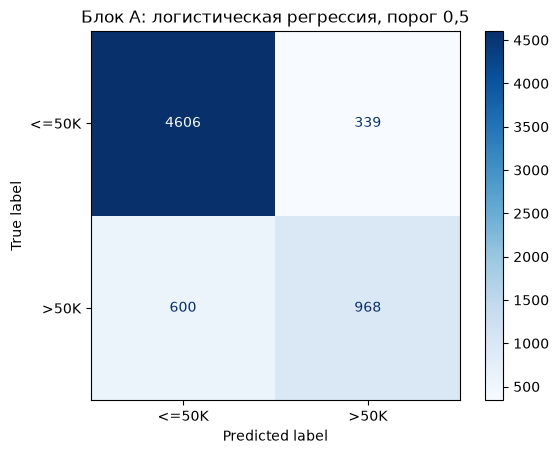

In [8]:
# Автор: Эркинбеков Айман
log_reg_a = LogisticRegression(max_iter=1000)
log_reg_a.fit(X_train_enc, y_train)
pred_a = log_reg_a.predict(X_test_enc)

acc_a = accuracy_score(y_test, pred_a)
cm_a = confusion_matrix(y_test, pred_a)
tn, fp, fn, tp = cm_a.ravel()

print(f"Accuracy: {acc_a:.3f}")
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

# Recall (полнота) = TP / (TP + FN) = какую долю людей с >50K модель нашла
recall_a = tp / (tp + fn)
print(f"Модель нашла {tp} из {tp + fn} людей с доходом >50K, это {recall_a:.1%} (recall)")

ConfusionMatrixDisplay(cm_a, display_labels=["<=50K", ">50K"]).plot(cmap="Blues")
plt.title("Блок A: логистическая регрессия, порог 0,5")
plt.show()

**Итог блока A.** Accuracy 0,856, но это всего на 10 пунктов лучше «тупой» модели, которая всем отвечает «<=50K» (0,759). Главное: модель нашла 968 из 1568 людей с доходом >50K, то есть **61,7%** (это recall). Остальных 600 человек (FN) банк пропустит. Это повод в блоке B выбрать метрику под заказчика и подобрать порог.

---
# Блок B. Основной

## B1. EDA: пропуски, выбросы, подозрительные признаки

*Автор: Айжигит*

EDA делаю **только на train**, чтобы решения не зависели от теста.

In [9]:
# Автор: Айжигит
train = X_train.copy()
train["income"] = y_train           # для удобства анализа добавим ответ

# 1) Явные пропуски: workclass и occupation пропадают вместе?
both = (train["workclass"].isna() & train["occupation"].isna()).sum()
print("Пропусков workclass:", train["workclass"].isna().sum(),
      "| из них occupation тоже пуст:", both)

# 2) Скрытые пропуски: occupation пуст, а workclass заполнен
hidden = train[train["occupation"].isna() & train["workclass"].notna()]
print("Occupation пуст при заполненном workclass:", len(hidden),
      "->", hidden["workclass"].value_counts().to_dict())

# 3) Отличаются ли люди с пропусками? Доля >50K среди них и среди остальных
has_na = train[["workclass", "occupation"]].isna().any(axis=1)
print(f"Доля >50K: с пропусками {train.loc[has_na, 'income'].mean():.3f}, "
      f"без пропусков {train.loc[~has_na, 'income'].mean():.3f}")

Пропусков workclass: 1473 | из них occupation тоже пуст: 1473
Occupation пуст при заполненном workclass: 6 -> {'Never-worked': 6}
Доля >50K: с пропусками 0.105, без пропусков 0.249


Пропуски в `workclass` и `occupation` идут **вместе**: это люди, про работу которых ничего не известно. Среди них доля >50K примерно в 2,5 раза ниже, чем у остальных. Значит, пропуск сам по себе несёт информацию. Заполнять его самым частым значением (`Private`, `Prof-specialty`) - значит выдавать этих людей за типичных работников. В пайплайне блока B заменяю пропуск на отдельную категорию `Unknown`.

Ещё скрытый пропуск: у `workclass = Never-worked` профессия пустая. Это не ошибка, у человека просто нет профессии, категория `Unknown` подходит и здесь.

In [10]:
# Автор: Айжигит
# Числовые признаки: описание и подозрительные значения
num_cols_all = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
display(train[num_cols_all].describe().T.round(1))

print("capital.gain = 99999:", (train["capital.gain"] == 99999).sum(),
      "чел., доля >50K среди них:", train.loc[train["capital.gain"] == 99999, "income"].mean())
print("hours.per.week = 99:", (train["hours.per.week"] == 99).sum())
print("age = 90:", (train["age"] == 90).sum())
print(f"capital.gain = 0 у {(train['capital.gain'] == 0).mean():.1%}, "
      f"capital.loss = 0 у {(train['capital.loss'] == 0).mean():.1%}")

,count,mean,std,min,25%,50%,75%,max
age,26048.0,38.6,13.6,17.0,28.0,37.0,48.0,90.0
fnlwgt,26048.0,190001.8,105510.3,12285.0,118194.2,178553.5,237457.8,1484705.0
education.num,26048.0,10.1,2.6,1.0,9.0,10.0,12.0,16.0
capital.gain,26048.0,1060.7,7299.1,0.0,0.0,0.0,0.0,99999.0
capital.loss,26048.0,88.0,405.0,0.0,0.0,0.0,0.0,4356.0
hours.per.week,26048.0,40.5,12.4,1.0,40.0,40.0,45.0,99.0


capital.gain = 99999: 124 чел., доля >50K среди них: 1.0
hours.per.week = 99: 72
age = 90: 37
capital.gain = 0 у 91.7%, capital.loss = 0 у 95.3%


,Выбросов по IQR
age,118
fnlwgt,779
education.num,990
capital.gain,2149
capital.loss,1223
hours.per.week,7225


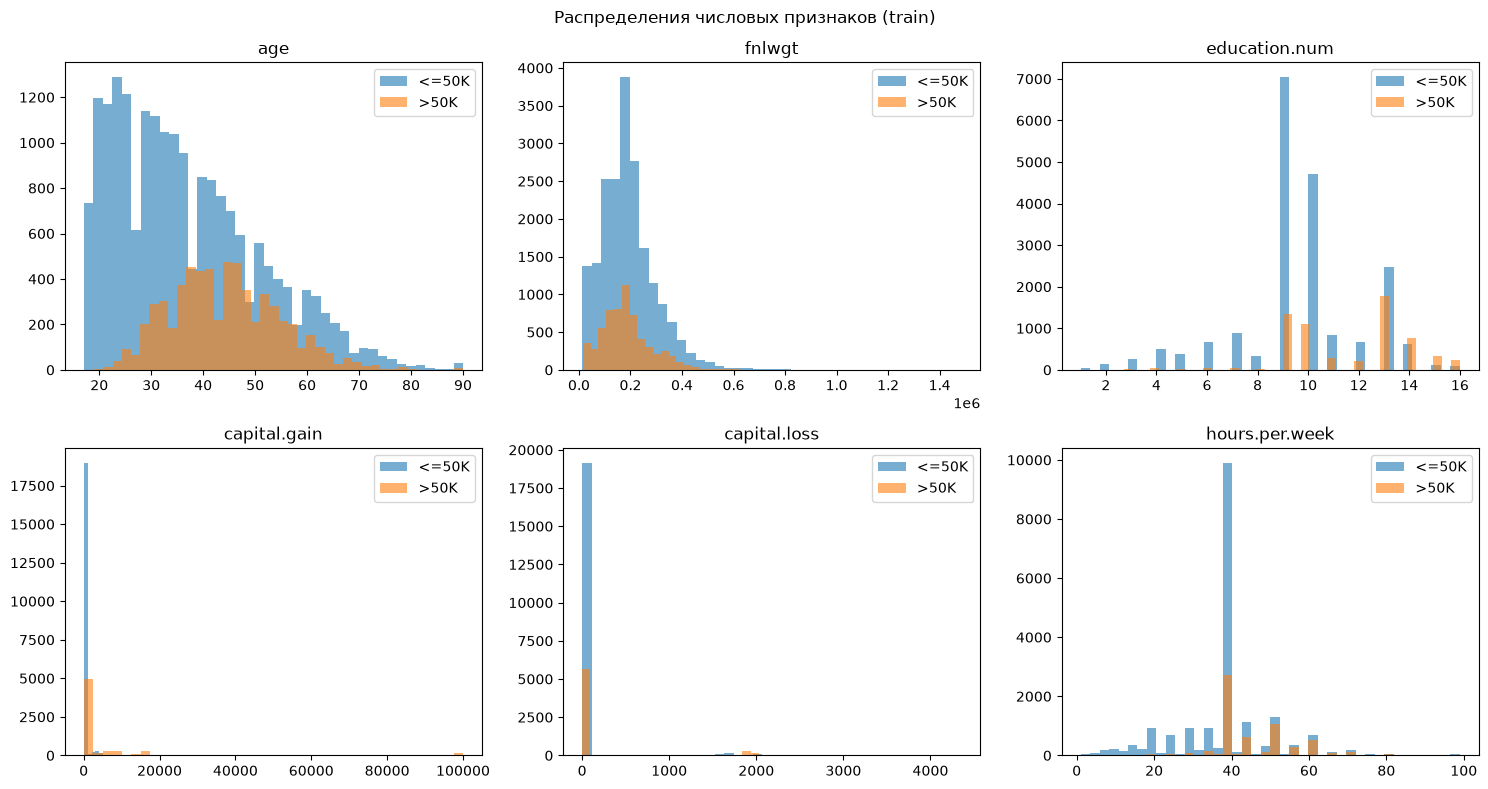

In [11]:
# Автор: Айжигит
# Выбросы по правилу IQR: значение дальше 1.5 * IQR от квартилей
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

display(pd.Series({c: iqr_outliers(train[c]) for c in num_cols_all}, name="Выбросов по IQR").to_frame())

# Графики: распределения по классам
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols_all):
    ax.hist(train.loc[train["income"] == 0, col], bins=40, alpha=0.6, label="<=50K")
    ax.hist(train.loc[train["income"] == 1, col], bins=40, alpha=0.6, label=">50K")
    ax.set_title(col)
    ax.legend()
plt.suptitle("Распределения числовых признаков (train)")
plt.tight_layout()
plt.show()

Что видно:

- `capital.gain = 99999` - это не реальная сумма, а **верхний предел** записи в переписи (top-coding). У всех таких людей доход >50K. Это не ошибка, но признак почти «выдаёт» ответ.
- `hours.per.week = 99` и `age = 90` - тоже верхние пределы. Значения правдоподобны, оставляю.
- `capital.gain` и `capital.loss` у 92% и 95% людей равны нулю. По IQR «выбросом» становится любой ненулевой доход с капитала, поэтому правило IQR тут не подходит. Удалять такие строки нельзя: это как раз самые информативные люди.
- Распределения `fnlwgt` у двух классов почти совпадают.

Дальше проверяю дубли признаков и строк.

In [12]:
# Автор: Айжигит
# education и education.num: одно и то же?
pairs = train.groupby("education")["education.num"].nunique()
print("Сколько разных education.num у каждого education (макс.):", pairs.max())
display(train.groupby("education")["education.num"].first().sort_values().to_frame().T)

# relationship и sex: Husband почти всегда мужчина, Wife почти всегда женщина
display(pd.crosstab(train["relationship"], train["sex"]))

# Полные дубли строк
print("Дублей строк в train:", train.duplicated().sum())

# Связь fnlwgt с ответом: корреляция почти ноль
print("Корреляция fnlwgt с income:", round(train["fnlwgt"].corr(train["income"]), 3))

Сколько разных education.num у каждого education (макс.): 1


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
education.num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16


sex,Female,Male
relationship,,
Husband,1,10585
Not-in-family,3134,3535
Other-relative,354,437
Own-child,1791,2245
Unmarried,2103,631
Wife,1230,2


Дублей строк в train: 16
Корреляция fnlwgt с income: -0.012


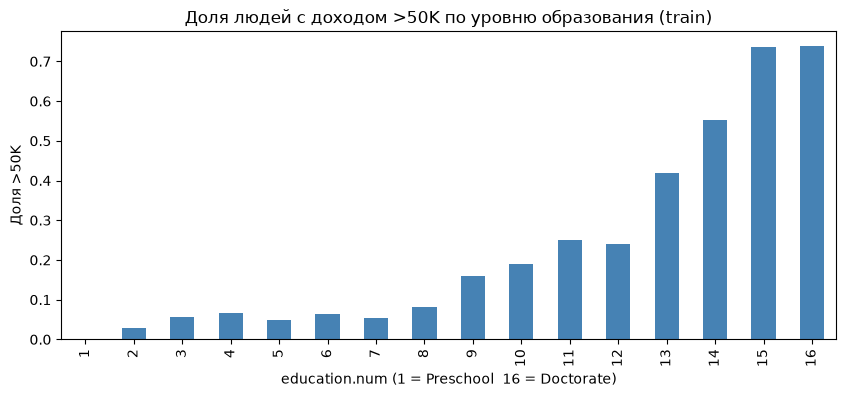

In [13]:
# Автор: Айжигит
# Доля >50K по уровню образования: признак сильный и монотонный
rate = train.groupby("education.num")["income"].mean()
rate.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Доля людей с доходом >50K по уровню образования (train)")
plt.xlabel("education.num (1 = Preschool  16 = Doctorate)")
plt.ylabel("Доля >50K")
plt.show()

**Итоги EDA:**

| Проблема | Что нашёл | Решение |
| --- | --- | --- |
| Пропуски `?` | 3 столбца, пропуски `workclass` и `occupation` идут вместе | отдельная категория `Unknown` |
| Скрытые пропуски | `Never-worked` без профессии; `capital.gain = 99999` - предел записи | `Unknown`; 99999 оставляю, отмечаю в блоке C |
| Выбросы | IQR помечает все ненулевые `capital.*` | не удаляю, это ценные люди |
| Дубль признака | `education` ↔ `education.num` один к одному | удаляю `education` |
| Бесполезный признак | `fnlwgt` - вес строки в выборке переписи, а не свойство человека, корреляция ≈ 0 | удаляю |
| Почти дубль | `relationship` (Husband/Wife) повторяет пол и семейное положение | оставляю для качества, обсуждаю в блоке C |
| Дубли строк | около 20 полных дублей в train | удаляю из train |

## B2. Pipeline + ColumnTransformer без утечки

*Автор: Эркинбеков Айман*

Все шаги обработки лежат **внутри** `Pipeline`. Когда кросс-валидация обучает модель на 4 фолдах, imputer и scaler тоже учатся только на этих 4 фолдах. Пятый фолд они не видят. Так утечки нет.

Сначала проверяю, что удаление `fnlwgt` и `education` не ухудшает качество.

In [14]:
# Автор: Эркинбеков Айман
# Убираем полные дубли из train (тест не трогаем)
dup_mask = X_train.assign(income=y_train).duplicated()
X_tr = X_train[~dup_mask]
y_tr = y_train[~dup_mask]
print("Удалено дублей:", dup_mask.sum(), "| train теперь:", X_tr.shape)

def make_preprocessor(num_features, cat_features):
    """Пайплайн обработки: числа и категории обрабатываются по-разному."""
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # на случай пропусков в числах
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        # пропуск -> отдельная категория "Unknown" (решение из EDA)
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        # min_frequency=20: редкие страны/категории объединяются в одну "infrequent"
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", numeric, num_features),
        ("cat", categorical, cat_features),
    ])

ALL_NUM = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
ALL_CAT = ["workclass", "education", "marital.status", "occupation",
           "relationship", "race", "sex", "native.country"]

# Признаки после удаления бесполезных
NUM = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
CAT = ["workclass", "marital.status", "occupation", "relationship", "race", "sex", "native.country"]

# StratifiedKFold(5): 5 частей, в каждой та же доля классов 24/76
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_scores(model, X_, y_, scoring=("f1", "roc_auc")):
    """Средние метрики по 5 фолдам."""
    res = cross_validate(model, X_, y_, cv=cv, scoring=list(scoring), n_jobs=-1)
    return {m: res[f"test_{m}"].mean() for m in scoring}

lr = LogisticRegression(max_iter=2000)
check = pd.DataFrame({
    "Все признаки": cv_scores(Pipeline([("prep", make_preprocessor(ALL_NUM, ALL_CAT)), ("model", lr)]), X_tr, y_tr),
    "Без fnlwgt и education": cv_scores(Pipeline([("prep", make_preprocessor(NUM, CAT)), ("model", lr)]), X_tr, y_tr),
}).T.round(4)
display(check)

Удалено дублей: 16 | train теперь: (26032, 14)


,f1,roc_auc
Все признаки,0.659,0.9060
Без fnlwgt и education,0.659,0.9058


Качество не изменилось (разница в четвёртом знаке). Значит, `fnlwgt` и `education` модели не нужны: первый - служебный вес переписи, второй - копия `education.num`. Удаляю их, модель стала проще.

## B3. Две модели на StratifiedKFold(5)

Сравниваю две модели из пройденных:

1. **Логистическая регрессия** - линейная, быстрая, хорошо объясняется (у каждого признака свой вес).
2. **Случайный лес** - много деревьев решений, каждое учится на случайной подвыборке строк и признаков, ответ - голосование. Ловит нелинейные зависимости (например, «женат И высшее образование»).

Обе модели обёрнуты в один и тот же пайплайн обработки.

In [15]:
# Автор: Эркинбеков Айман
models = {
    "Логистическая регрессия": Pipeline([
        ("prep", make_preprocessor(NUM, CAT)),
        ("model", LogisticRegression(max_iter=2000)),
    ]),
    "Случайный лес": Pipeline([
        ("prep", make_preprocessor(NUM, CAT)),
        ("model", RandomForestClassifier(
            n_estimators=300,        # 300 деревьев
            min_samples_leaf=3,      # в листе минимум 3 человека -> меньше переобучения
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ]),
}

metrics = ("accuracy", "precision", "recall", "f1", "roc_auc")
cv_table = pd.DataFrame({name: cv_scores(m, X_tr, y_tr, metrics) for name, m in models.items()}).T
display(cv_table.round(3))

,accuracy,precision,recall,f1,roc_auc
Логистическая регрессия,0.851,0.732,0.600,0.659,0.906
Случайный лес,0.863,0.781,0.602,0.680,0.917


## B4. Метрика под заказчика и подбор порога

**Почему не accuracy.** Классы 76/24, и accuracy в основном показывает, как модель угадывает большой класс `<=50K`.

**Почему F1.** У банка две ошибки стоят примерно одинаково: лишнее предложение (FP) бьёт по **precision**, пропущенный клиент (FN) бьёт по **recall**. F1 - среднее гармоническое precision и recall, оно высокое, только если обе величины высокие. Поэтому главная метрика - **F1 для класса >50K**. Дополнительно смотрю ROC-AUC (качество ранжирования, не зависит от порога) и общее число ошибок FP + FN.

**Порог.** По умолчанию модель говорит «>50K» при вероятности ≥ 0,5. Из-за дисбаланса это слишком строго, recall низкий. Подбираю порог так:

1. `cross_val_predict` даёт для каждой строки train вероятность от модели, которая эту строку **не видела** (out-of-fold).
2. На этих вероятностях перебираю пороги и беру тот, где F1 максимальный.
3. Тест в подборе не участвует.

Лучшая модель по F1 на кросс-валидации: Случайный лес


Порог с максимальным F1: 0.38


,Precision,Recall,F1,FP,FN,Ошибок FP+FN
Порог,,,,,,
0.30,0.612,0.819,0.701,3256,1132,4388
0.35,0.657,0.769,0.708,2524,1447,3971
0.38,0.687,0.739,0.712,2110,1635,3745
0.40,0.704,0.718,0.711,1890,1769,3659
0.45,0.740,0.662,0.699,1457,2118,3575
0.50,0.781,0.602,0.680,1060,2498,3558


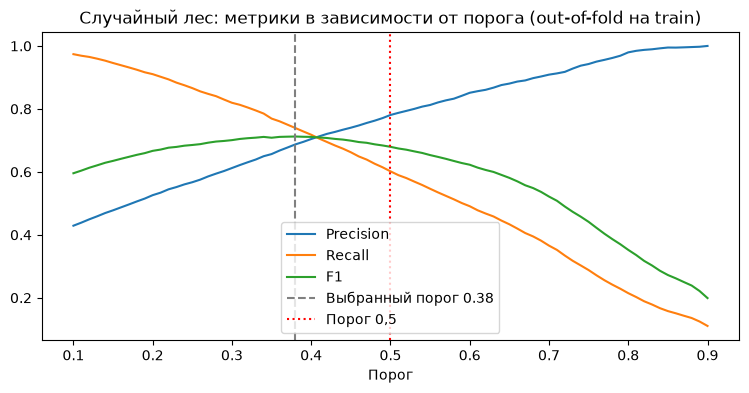

In [16]:
# Автор: Эркинбеков Айман
best_name = cv_table["f1"].idxmax()          # выбираем модель с лучшим F1 на CV
best_model = models[best_name]
print("Лучшая модель по F1 на кросс-валидации:", best_name)

# Вероятности класса 1 "вне фолда" для каждой строки train
oof_proba = cross_val_predict(best_model, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in np.arange(0.10, 0.91, 0.01):
    pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_tr, pred).ravel()
    rows.append({"Порог": round(t, 2), "Precision": precision_score(y_tr, pred),
                 "Recall": recall_score(y_tr, pred), "F1": f1_score(y_tr, pred),
                 "FP": fp, "FN": fn, "Ошибок FP+FN": fp + fn})
thr_table = pd.DataFrame(rows)

best_thr = thr_table.loc[thr_table["F1"].idxmax(), "Порог"]
print("Порог с максимальным F1:", best_thr)
show = sorted({0.3, 0.35, 0.4, float(best_thr), 0.45, 0.5})
display(thr_table.set_index("Порог").loc[show].round(3))

plt.figure(figsize=(9, 4))
for col in ["Precision", "Recall", "F1"]:
    plt.plot(thr_table["Порог"], thr_table[col], label=col)
plt.axvline(best_thr, color="gray", linestyle="--", label=f"Выбранный порог {best_thr}")
plt.axvline(0.5, color="red", linestyle=":", label="Порог 0,5")
plt.xlabel("Порог")
plt.title(f"{best_name}: метрики в зависимости от порога (out-of-fold на train)")
plt.legend()
plt.show()

### Финальная проверка на отложенном тесте

Обучаю выбранную модель на всём train и **один раз** проверяю на тесте при пороге 0,5 и при выбранном пороге.

,Accuracy,Recall,Precision,F1,ROC-AUC,FP,FN,Ошибок FP+FN
"Блок A (LogReg, 0.5)",0.856,0.617,0.741,0.673,0.908,339.0,600.0,939.0
"Случайный лес, порог 0.5",0.870,0.622,0.793,0.697,0.922,255.0,592.0,847.0
"Случайный лес, порог 0.38",0.859,0.762,0.686,0.722,0.922,546.0,373.0,919.0


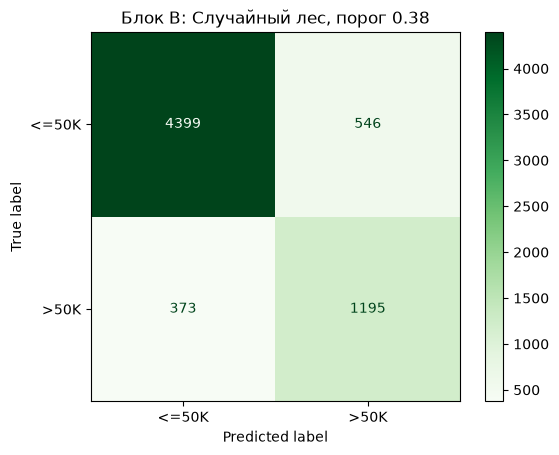

In [17]:
# Автор: Эркинбеков Айман
final_model = clone(best_model).fit(X_tr, y_tr)
test_proba = final_model.predict_proba(X_test)[:, 1]

def test_report(threshold):
    pred = (test_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, test_proba), "FP": fp, "FN": fn, "Ошибок FP+FN": fp + fn}

final_table = pd.DataFrame({
    "Блок A (LogReg, 0.5)": {"Accuracy": acc_a, "Recall": recall_a,
                             "Precision": precision_score(y_test, pred_a), "F1": f1_score(y_test, pred_a),
                             "ROC-AUC": roc_auc_score(y_test, log_reg_a.predict_proba(X_test_enc)[:, 1]),
                             "FP": cm_a[0, 1], "FN": cm_a[1, 0], "Ошибок FP+FN": cm_a[0, 1] + cm_a[1, 0]},
    f"{best_name}, порог 0.5": test_report(0.5),
    f"{best_name}, порог {best_thr}": test_report(best_thr),
}).T
display(final_table.round(3))

final_pred = (test_proba >= best_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred), display_labels=["<=50K", ">50K"]).plot(cmap="Greens")
plt.title(f"Блок B: {best_name}, порог {best_thr}")
plt.show()

## B5. Вывод

**Результаты на отложенном тесте:**

| Модель | F1 | Recall | Precision | ROC-AUC | FP + FN |
| --- | --- | --- | --- | --- | --- |
| Блок A: логистическая регрессия, порог 0,5 | 0,673 | 0,617 | 0,741 | 0,908 | 939 |
| Случайный лес, порог 0,5 | 0,697 | 0,622 | 0,793 | 0,922 | 847 |
| **Случайный лес, порог 0,38** | **0,722** | **0,762** | 0,686 | 0,922 | 919 |

- На кросс-валидации случайный лес лучше логистической регрессии и по F1 (0,680 против 0,659), и по ROC-AUC (0,917 против 0,906). На тесте картина та же, значит, модель не переобучена под кросс-валидацию.
- Порог 0,38 поднял recall с 62% до 76%: банк найдёт на 219 состоятельных клиентов больше (FN 592 → 373). Цена: на 291 больше лишних предложений (FP 255 → 546).
- **Оговорка про порог.** Если банк считает ошибки строго равными по деньгам, то нужно минимизировать FP + FN, и тогда лучше порог около 0,45-0,5 (847 ошибок против 919). Порог 0,38 выбран по F1, потому что «сопоставимы» не значит «точно равны», и F1 держит баланс между пропусками и лишними предложениями. Если банк назовёт точную цену ошибки, порог надо пересчитать тем же способом.

**Можно ли отдавать модель?** Как инструмент для **отбора кандидатов на рассылку** - да: она находит 3 из 4 людей с высоким доходом, и 2 из 3 её предложений попадают в цель (при случайной рассылке попадала бы только 1 из 4). Оговорки:

1. Значительная часть качества держится на `capital.gain/loss`, которые банк может не знать (блок C1).
2. Модель использует пол, расу, семейное положение и страну рождения, а для кредитного продукта это недопустимо (блок C4). Перед внедрением их нужно убрать, качество при этом падает.
3. Данные - перепись США 1994 года. Порог 50K тогда соответствует примерно вдвое большей сумме сегодня. Модель нужно переобучить на свежих данных клиентов банка.

---
# Блок C. Продвинутый

*Автор: Айжигит*

## C1. Все проблемы данных и потенциальные утечки

Утечка (data leakage) - когда модель при обучении получает информацию, которой у неё не будет в реальной работе. Тогда качество на проверке завышено.

Проверяю главную подозрительную вещь: **`capital.gain` и `capital.loss`**. Доход в переписи - это *весь* доход человека, включая доход с капитала. То есть `capital.gain` - это **часть самого ответа**. Кроме того, банк при рассылке обычно не знает доход клиента с инвестиций. Смотрю, сколько качества держится на этих признаках.

In [18]:
# Автор: Айжигит
NUM_NO_CAP = ["age", "education.num", "hours.per.week"]

no_cap_model = Pipeline([
    ("prep", make_preprocessor(NUM_NO_CAP, CAT)),
    ("model", clone(best_model.named_steps["model"])),
])

leak_check = pd.DataFrame({
    "С capital.gain/loss": cv_scores(best_model, X_tr, y_tr),
    "Без capital.gain/loss": cv_scores(no_cap_model, X_tr, y_tr),
}).T.round(3)
display(leak_check)

# Сколько людей с 99999 в тесте и как модель на них отвечает
mask_99 = X_test["capital.gain"] == 99999
print("В тесте capital.gain=99999:", mask_99.sum(), "чел., модель дала >50K:", final_pred[mask_99.values].sum())

,f1,roc_auc
С capital.gain/loss,0.680,0.917
Без capital.gain/loss,0.623,0.892


В тесте capital.gain=99999: 35 чел., модель дала >50K: 35


Без `capital.gain/loss` F1 падает с 0,680 до 0,623, ROC-AUC с 0,917 до 0,892. Значит, заметная часть качества держится на признаках, которые сами входят в доход. Все 35 человек в тесте с `capital.gain = 99999` модель отнесла к >50K - тут она просто «читает ответ».

Это не классическая утечка (признак известен до ответа в самой переписи), но для банка это **риск**: если у банка нет данных о доходе с капитала, реальное качество будет ближе к 0,62, а не к 0,68. Честная оценка для заказчика - вариант без этих признаков.

**Сводная таблица проблем:**

| № | Проблема | Как нашли | Что сделали |
| --- | --- | --- | --- |
| 1 | Пропуски записаны как `?` | условие задания, `df.info()` | `na_values="?"` |
| 2 | Пропуски `workclass` и `occupation` идут вместе, у таких людей доход ниже | сравнили долю >50K с пропуском и без | категория `Unknown` вместо самого частого значения |
| 3 | Скрытый пропуск: `Never-worked` без профессии | пропуск `occupation` при заполненном `workclass` | тоже `Unknown` |
| 4 | `capital.gain = 99999` - предел записи, у всех таких >50K | `describe()`, максимум | оставили как есть, отметили как почти-утечку |
| 5 | `capital.gain/loss` - часть дохода, банк их обычно не знает | смысл признака + сравнение на CV | показали качество без них, это честная оценка для банка |
| 6 | `education` дублирует `education.num` | `groupby` - каждой категории одно число | удалили `education` |
| 7 | `fnlwgt` - вес строки в переписи | смысл признака, корреляция ≈ 0, CV без него не хуже | удалили |
| 8 | `relationship` повторяет пол (Husband/Wife) | `crosstab` с `sex` | оставили, но это прокси пола (см. C4) |
| 9 | Полные дубли строк | `duplicated()` | удалили из train |
| 10 | Утечка через обработку | - | все шаги в `Pipeline`, `fit` только на train и внутри фолдов |
| 11 | Утечка через подбор порога | - | порог выбран на out-of-fold вероятностях train, не на тесте |
| 12 | Дисбаланс 76/24 | `value_counts` | метрика F1, подбор порога, методы в C2 |
| 13 | Редкие страны (десятки стран по 1-20 человек) | `value_counts` | `min_frequency=20` объединяет их в одну группу |

## C2. Методы против дисбаланса внутри кросс-валидации

Сравниваю на лучшей модели из блока B:

1. **Без коррекции** - базовый вариант.
2. **class_weight="balanced"** - ошибка на редком классе штрафуется сильнее (вес ≈ 76/24 ≈ 3).
3. **Oversampling** - случайно дублирую строки класса >50K, пока классов не станет поровну.
4. **Undersampling** - случайно выкидываю часть строк класса <=50K до равенства.

Важно: oversampling и undersampling делаю **только на обучающих фолдах**. Если сначала размножить строки, а потом делить на фолды, копии одной строки попадут и в обучение, и в проверку - это утечка, и качество будет завышено.

Метрика заказчика - F1. Для каждого метода считаю F1 при пороге 0,5 и F1 при лучшем пороге (подобран по out-of-fold вероятностям), а также ROC-AUC.

In [19]:
# Автор: Айжигит
rng = np.random.default_rng(RANDOM_STATE)

def resample(X_, y_, mode):
    """Балансирует классы ТОЛЬКО в переданной (обучающей) части."""
    idx_pos = np.where(y_.values == 1)[0]
    idx_neg = np.where(y_.values == 0)[0]
    if mode == "over":    # дублируем редкий класс
        idx_pos = rng.choice(idx_pos, size=len(idx_neg), replace=True)
    elif mode == "under": # урезаем частый класс
        idx_neg = rng.choice(idx_neg, size=len(idx_pos), replace=False)
    idx = np.concatenate([idx_pos, idx_neg])
    return X_.iloc[idx], y_.iloc[idx]

def cv_imbalance(method):
    """Ручной цикл кросс-валидации: на каждом фолде своя балансировка train-части."""
    oof = np.zeros(len(y_tr))
    for train_idx, val_idx in cv.split(X_tr, y_tr):
        X_f, y_f = X_tr.iloc[train_idx], y_tr.iloc[train_idx]
        model = clone(best_model)
        if method == "class_weight":
            model.set_params(model__class_weight="balanced")
        elif method in ("over", "under"):
            X_f, y_f = resample(X_f, y_f, method)   # валидационный фолд не трогаем!
        model.fit(X_f, y_f)
        oof[val_idx] = model.predict_proba(X_tr.iloc[val_idx])[:, 1]
    # F1 при пороге 0.5 и при лучшем пороге
    thr_grid = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_tr, (oof >= t).astype(int)) for t in thr_grid]
    pred05 = (oof >= 0.5).astype(int)
    return {"Precision (0.5)": precision_score(y_tr, pred05), "Recall (0.5)": recall_score(y_tr, pred05),
            "F1 (0.5)": f1_score(y_tr, pred05), "Лучший порог": thr_grid[int(np.argmax(f1s))],
            "F1 (лучший порог)": max(f1s), "ROC-AUC": roc_auc_score(y_tr, oof)}

methods = {"Без коррекции": "none", "class_weight=balanced": "class_weight",
           "Oversampling": "over", "Undersampling": "under"}
imb_table = pd.DataFrame({name: cv_imbalance(m) for name, m in methods.items()}).T
display(imb_table.round(3))

,Precision (0.5),Recall (0.5),F1 (0.5),Лучший порог,F1 (лучший порог),ROC-AUC
Без коррекции,0.781,0.602,0.680,0.38,0.712,0.917
class_weight=balanced,0.586,0.854,0.695,0.61,0.709,0.916
Oversampling,0.606,0.828,0.700,0.61,0.712,0.916
Undersampling,0.573,0.868,0.691,0.63,0.707,0.915


**Что видно:**

- При пороге 0,5 все три метода поднимают F1 (0,680 → 0,69-0,70) и сильно поднимают recall (0,60 → 0,83-0,87), но precision падает (0,78 → 0,57-0,61).
- При **подобранном пороге** все четыре варианта дают практически одинаковый F1 ≈ 0,71, а ROC-AUC не меняется (0,915-0,917).
- Вывод: балансировка классов здесь по сути делает то же, что и сдвиг порога, - сдвигает вероятности вверх. Модель от неё лучше «различать» людей не стала (ROC-AUC тот же).

Поэтому в финальной модели оставляю **без коррекции + подбор порога**: это самый простой вариант с тем же качеством. Undersampling ещё и выбрасывает около половины данных, oversampling создаёт копии строк и увеличивает время обучения.

## C3. Анализ ошибок: на каких группах модель ошибается чаще

Беру финальную модель из блока B и её предсказания на тесте. Для каждой группы людей считаю:

- **FNR** (доля пропусков) = FN / все люди с >50K в группе - скольких богатых клиентов банк упустит;
- **FPR** (доля ложных предложений) = FP / все люди с <=50K в группе - скольким зря отправят предложение;
- **Ошибок, %** - общая доля неверных ответов.

In [20]:
# Автор: Айжигит
analysis = X_test.copy()
analysis["y_true"] = y_test.values
analysis["y_pred"] = final_pred
analysis["age_group"] = pd.cut(analysis["age"], [16, 25, 35, 45, 55, 65, 91],
                               labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"], right=False)
analysis["hours_group"] = pd.cut(analysis["hours.per.week"], [0, 35, 41, 50, 100],
                                 labels=["<35", "35-40", "41-49", "50+"], right=False)
analysis["edu_group"] = pd.cut(analysis["education.num"], [0, 9, 10, 13, 17],
                               labels=["Ниже школы", "Школа", "Колледж/Assoc", "Бакалавр+"], right=False)

def group_errors(col):
    rows = []
    for g, part in analysis.groupby(col, observed=True):
        pos = part["y_true"] == 1
        neg = ~pos
        rows.append({
            "Признак": col, "Группа": g, "Людей": len(part),
            "Доля >50K": pos.mean(),
            "FNR (пропуски)": ((part["y_pred"] == 0) & pos).sum() / max(pos.sum(), 1),
            "FPR (ложные)": ((part["y_pred"] == 1) & neg).sum() / max(neg.sum(), 1),
            "Ошибок, %": (part["y_pred"] != part["y_true"]).mean() * 100,
        })
    return pd.DataFrame(rows)

group_cols = ["sex", "race", "age_group", "edu_group", "marital.status", "hours_group"]
err_table = pd.concat([group_errors(c) for c in group_cols], ignore_index=True)
err_table = err_table[err_table["Людей"] >= 30]       # слишком маленькие группы не оцениваем
display(err_table.round(3))

,Признак,Группа,Людей,Доля >50K,FNR (пропуски),FPR (ложные),"Ошибок, %"
0,sex,Female,2158,0.114,0.294,0.038,6.673
1,sex,Male,4355,0.304,0.228,0.156,17.796
2,race,Amer-Indian-Eskimo,73,0.123,0.556,0.047,10.959
3,race,Asian-Pac-Islander,200,0.260,0.250,0.176,19.500
4,race,Black,662,0.140,0.323,0.046,8.459
5,race,Other,45,0.089,0.000,0.024,2.222
6,race,White,5533,0.255,0.230,0.119,14.730
7,age_group,17-25,1129,0.008,0.778,0.006,1.240
8,age_group,26-35,1698,0.169,0.348,0.062,11.072
9,age_group,36-45,1606,0.337,0.223,0.181,19.552


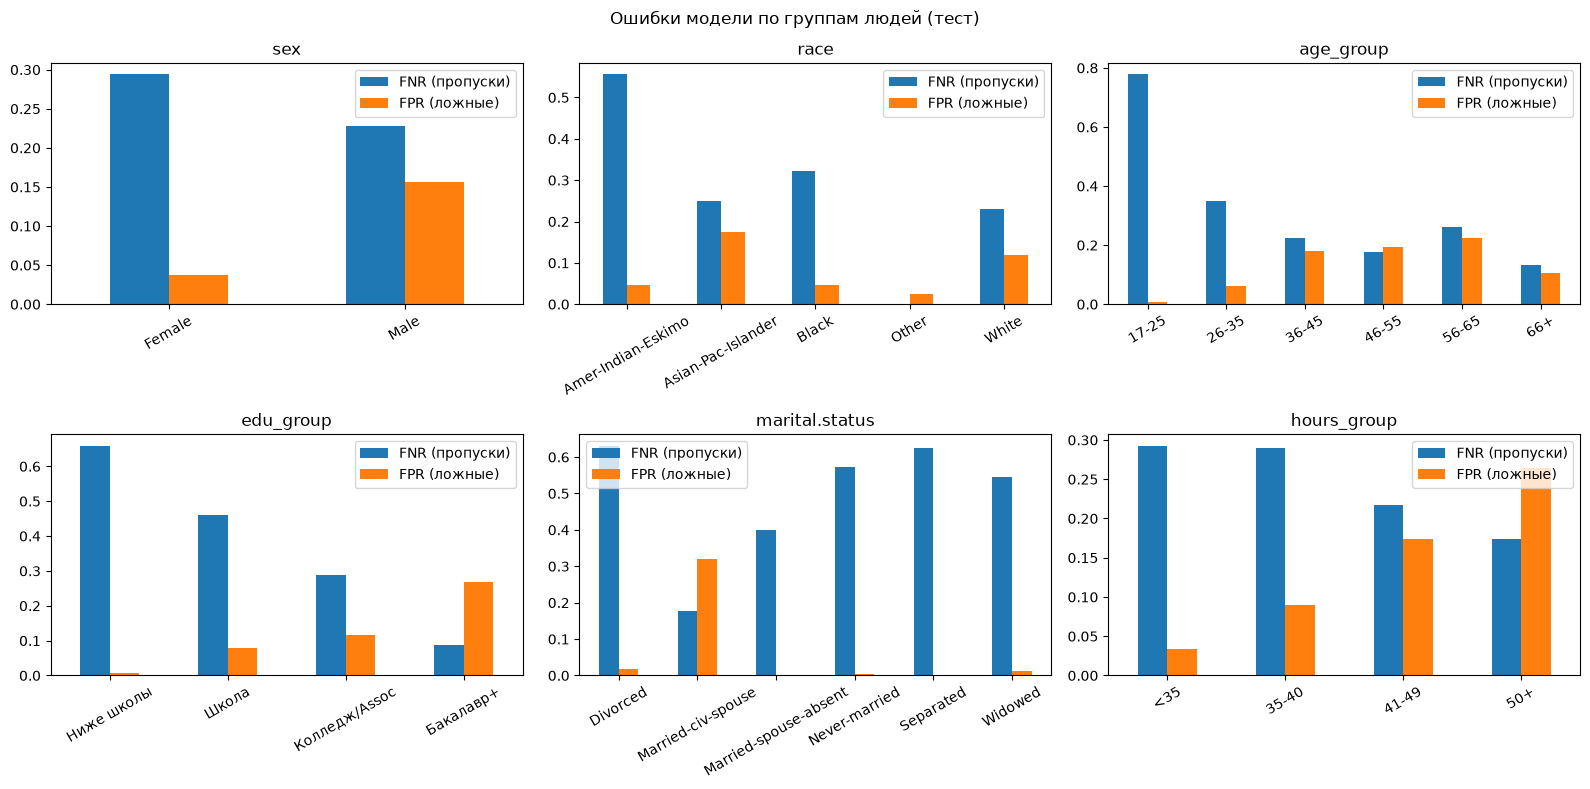

In [21]:
# Автор: Айжигит
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), group_cols):
    part = err_table[err_table["Признак"] == col].set_index("Группа")
    part[["FNR (пропуски)", "FPR (ложные)"]].plot(kind="bar", ax=ax, rot=30)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Ошибки модели по группам людей (тест)")
plt.tight_layout()
plt.show()

**Где модель ошибается чаще:**

- **Пропускает (высокий FNR)** состоятельных людей, которые не похожи на «типичного богатого»: молодых 17-25 лет (FNR 0,78), без высшего образования (0,66 у «ниже школы», 0,46 у выпускников школы), не состоящих в браке (разведённые 0,63, никогда не женатые 0,57). Модель выучила шаблон «богатый = женат + образован + средний возраст».
- **Зря предлагает (высокий FPR)** женатым (FPR 0,32), людям с высшим образованием (0,27) и работающим 50+ часов в неделю (0,27). У мужчин FPR 0,156, у женщин 0,038. Мужчинам модель чаще говорит «>50K», потому что в данных доля >50K у мужчин 30%, а у женщин 11%.
- **Женщин** модель пропускает чаще (FNR 0,29 против 0,23 у мужчин): состоятельную женщину найти сложнее.
- По расам: у небольших групп (Amer-Indian-Eskimo - 73 человека, Black - 662) FNR выше (0,56 и 0,32), но выборки маленькие, выводы неуверенные.

Для банка это значит: модель систематически недооценивает молодых, незамужних и женщин с высоким доходом.

## C4. Ограничения решения и допустимость признаков

Модель предназначена для **кредитного** продукта. В США закон Equal Credit Opportunity Act (ECOA) запрещает принимать кредитные решения на основе расы, цвета кожи, религии, национального происхождения, пола, семейного положения и возраста. Во многих других странах есть похожие запреты дискриминации.

В наших данных к таким признакам относятся:

| Признак | Почему проблема |
| --- | --- |
| `sex` | пол - защищённый признак |
| `race` | раса - защищённый признак |
| `native.country` | национальное происхождение |
| `marital.status` | семейное положение |
| `relationship` | Husband/Wife - фактически пол + семейное положение (прокси) |
| `age` | возраст - защищён; можно использовать только в ограниченных случаях |

Проверяю, сколько качества теряет модель без них (возраст оставляю, отмечая риск).

In [22]:
# Автор: Айжигит
CAT_FAIR = ["workclass", "occupation"]       # убрали sex, race, native.country, marital.status, relationship

fair_model = Pipeline([
    ("prep", make_preprocessor(NUM, CAT_FAIR)),
    ("model", clone(best_model.named_steps["model"])),
])

fair_table = pd.DataFrame({
    "Все признаки": cv_scores(best_model, X_tr, y_tr),
    "Без защищённых признаков": cv_scores(fair_model, X_tr, y_tr),
}).T.round(3)
display(fair_table)

# Остаются ли различия между мужчинами и женщинами у "честной" модели?
fair_model.fit(X_tr, y_tr)
fair_pred = (fair_model.predict_proba(X_test)[:, 1] >= best_thr).astype(int)
by_sex = pd.DataFrame({
    "Доля получивших предложение (полная)": pd.Series(final_pred, index=X_test.index).groupby(X_test["sex"]).mean(),
    "Доля получивших предложение (без защищённых)": pd.Series(fair_pred, index=X_test.index).groupby(X_test["sex"]).mean(),
    "Реальная доля >50K": y_test.groupby(X_test["sex"]).mean(),
}).round(3)
display(by_sex)

,f1,roc_auc
Все признаки,0.680,0.917
Без защищённых признаков,0.591,0.866


,Доля получивших предложение (полная),Доля получивших предложение (без защищённых),Реальная доля >50K
sex,,,
Female,0.114,0.133,0.114
Male,0.344,0.274,0.304


Без защищённых признаков F1 падает с 0,680 до 0,591, ROC-AUC с 0,917 до 0,866. Разрыв между мужчинами и женщинами сократился (доля предложений 0,344/0,114 → 0,274/0,133), но **не исчез**: пол «просачивается» через другие признаки (профессия, часы работы). Убрать столбец недостаточно, такие признаки называют **прокси**.

**Ограничения решения:**

1. **Защищённые признаки.** Для кредитного продукта `sex`, `race`, `native.country`, `marital.status`, `relationship` использовать нельзя. Модель без них слабее (F1 0,59), и это честная цена законности. Остаточную разницу по группам нужно регулярно проверять.
2. **Возраст.** Оставлен, но это тоже защищённый признак; использовать можно только с разрешения юристов банка.
3. **Капитальный доход.** `capital.gain/loss` - часть ответа, банк их обычно не знает. Без них качество ниже (F1 0,62).
4. **Устаревшие данные.** Перепись США 1994 года: другие зарплаты, другая структура профессий, только жители США. Для реального банка модель нужно переобучить на его клиентах.
5. **Модель предсказывает доход, а не платёжеспособность.** Высокий доход не значит, что человек вернёт долг. Для кредитной карты нужен отдельный кредитный скоринг.
6. **Порог.** Подобран под F1 при «сопоставимых» ошибках. Если банк назовёт точные цены ошибок, порог надо пересчитать.
7. **Ошибки по группам.** Модель хуже находит состоятельных молодых, незамужних и женщин (C3), их стоит отслеживать отдельно.